In [2]:
import pandas as pd
import numpy as np

import plotly as pt
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import make_scorer, roc_auc_score, average_precision_score, precision_score
from sklearn.preprocessing import OrdinalEncoder

from sklearn.metrics import classification_report

from xgboost import XGBClassifier
#For OS
import os


In [3]:
Test_Data = pd.read_csv('data/application_test.csv')
Train_Data = pd.read_csv('data/application_train.csv')

In [23]:
print(Test_Data.head())


   SK_ID_CURR NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  \
0      100001         Cash loans           F            N               Y   
1      100005         Cash loans           M            N               Y   
2      100013         Cash loans           M            Y               Y   
3      100028         Cash loans           F            N               Y   
4      100038         Cash loans           M            Y               N   

   CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  \
0             0          135000.0    568800.0      20560.5         450000.0   
1             0           99000.0    222768.0      17370.0         180000.0   
2             0          202500.0    663264.0      69777.0         630000.0   
3             2          315000.0   1575000.0      49018.5        1575000.0   
4             1          180000.0    625500.0      32067.0         625500.0   

   ... FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG

In [24]:
print(Train_Data.head())

   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   ...  FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOCUMENT_20 FLAG_DOCUMENT_21  \
0  ...                 0             

In [25]:
print("Train_Data:", Train_Data.shape)
print("Test_Data:", Test_Data.shape)

Train_Data: (307511, 122)
Test_Data: (48744, 121)


In [26]:
print(set(Train_Data.columns) - set(Test_Data.columns))
print(set(Test_Data.columns) - set(Train_Data.columns))

{'TARGET'}
set()


In [27]:
#Train data info
Train_Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 286.2 MB


In [28]:
Train_Data.sample(5)

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
241495,379645,0,Cash loans,F,N,Y,0,67500.0,239850.0,23850.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
170688,297817,0,Cash loans,F,N,N,1,144000.0,645889.5,23328.0,...,0,0,0,0,0.0,0.0,0.0,0.0,2.0,7.0
194821,325901,0,Revolving loans,F,N,Y,0,225000.0,225000.0,11250.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,2.0
171398,298643,0,Cash loans,F,N,Y,0,67500.0,225000.0,23053.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,3.0
143046,265855,0,Cash loans,F,N,Y,0,180000.0,1264428.0,37098.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,5.0


In [29]:
Train_Data.tail()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


In [30]:
#Column understand
print(Train_Data.columns.tolist())

['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELE

In [4]:
#Columns in list
for i, col in enumerate(Train_Data.columns, start=1):
    print(i, col)

1 SK_ID_CURR
2 TARGET
3 NAME_CONTRACT_TYPE
4 CODE_GENDER
5 FLAG_OWN_CAR
6 FLAG_OWN_REALTY
7 CNT_CHILDREN
8 AMT_INCOME_TOTAL
9 AMT_CREDIT
10 AMT_ANNUITY
11 AMT_GOODS_PRICE
12 NAME_TYPE_SUITE
13 NAME_INCOME_TYPE
14 NAME_EDUCATION_TYPE
15 NAME_FAMILY_STATUS
16 NAME_HOUSING_TYPE
17 REGION_POPULATION_RELATIVE
18 DAYS_BIRTH
19 DAYS_EMPLOYED
20 DAYS_REGISTRATION
21 DAYS_ID_PUBLISH
22 OWN_CAR_AGE
23 FLAG_MOBIL
24 FLAG_EMP_PHONE
25 FLAG_WORK_PHONE
26 FLAG_CONT_MOBILE
27 FLAG_PHONE
28 FLAG_EMAIL
29 OCCUPATION_TYPE
30 CNT_FAM_MEMBERS
31 REGION_RATING_CLIENT
32 REGION_RATING_CLIENT_W_CITY
33 WEEKDAY_APPR_PROCESS_START
34 HOUR_APPR_PROCESS_START
35 REG_REGION_NOT_LIVE_REGION
36 REG_REGION_NOT_WORK_REGION
37 LIVE_REGION_NOT_WORK_REGION
38 REG_CITY_NOT_LIVE_CITY
39 REG_CITY_NOT_WORK_CITY
40 LIVE_CITY_NOT_WORK_CITY
41 ORGANIZATION_TYPE
42 EXT_SOURCE_1
43 EXT_SOURCE_2
44 EXT_SOURCE_3
45 APARTMENTS_AVG
46 BASEMENTAREA_AVG
47 YEARS_BEGINEXPLUATATION_AVG
48 YEARS_BUILD_AVG
49 COMMONAREA_AVG
50 ELEVATORS_A

In [32]:
print("Duplicate rows:", Train_Data.duplicated().sum())
print("Duplicate SK_ID_CURR:", Train_Data["SK_ID_CURR"].duplicated().sum())

Duplicate rows: 0
Duplicate SK_ID_CURR: 0


In [33]:
#missing values
missing = Train_Data.isna().sum().sort_values(ascending=False)

print(missing.head(20))

COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
FLOORSMIN_MODE              208642
FLOORSMIN_AVG               208642
FLOORSMIN_MEDI              208642
YEARS_BUILD_AVG             204488
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
OWN_CAR_AGE                 202929
LANDAREA_MEDI               182590
LANDAREA_AVG                182590
LANDAREA_MODE               182590
dtype: int64


In [34]:
#in percentage
missing_pct = (
    Train_Data.isna().mean() * 100
).sort_values(ascending=False)

print(missing_pct.head(20))

COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
FLOORSMIN_MEDI              67.848630
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_MEDI               59.376738
LANDAREA_AVG                59.376738
LANDAREA_MODE               59.376738
dtype: float64


In [35]:
#Target distribution
print(
    Train_Data["TARGET"]
    .value_counts(normalize=True)
    .mul(100)
)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


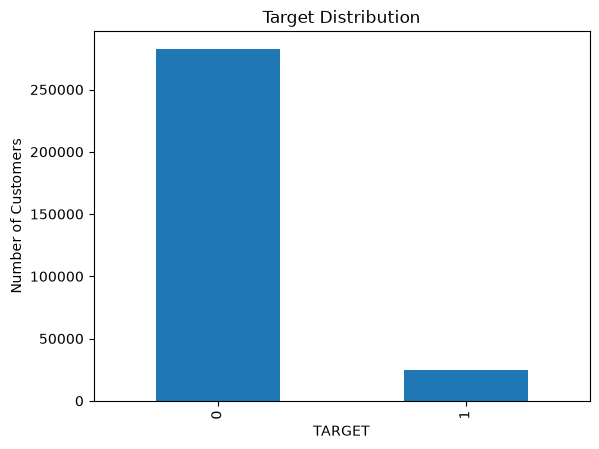

In [ ]:
# To check the distrivution of the "Target"
Train_Data["TARGET"].value_counts().plot(kind="bar")

plt.title("Target Distribution")
plt.xlabel("TARGET")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
# To get the statistics summary of the Train_Data
Train_Data.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


In [38]:
#Relationship with Target
Train_Data.groupby("TARGET")["AMT_INCOME_TOTAL"].median()

TARGET
0    148500.0
1    135000.0
Name: AMT_INCOME_TOTAL, dtype: float64

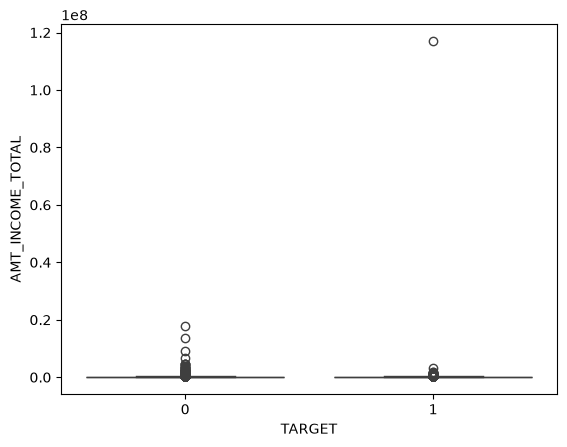

In [39]:
#Distribution
sns.boxplot(
    data=Train_Data,
    x="TARGET",
    y="AMT_INCOME_TOTAL"
)

plt.show()

In [40]:
Train_Data.isnull().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

In [41]:
missing = Train_Data.isnull().sum().sort_values(ascending=False)

for column, count in missing.items():
    print(f"{column}: {count}")

COMMONAREA_AVG: 214865
COMMONAREA_MODE: 214865
COMMONAREA_MEDI: 214865
NONLIVINGAPARTMENTS_MEDI: 213514
NONLIVINGAPARTMENTS_MODE: 213514
NONLIVINGAPARTMENTS_AVG: 213514
FONDKAPREMONT_MODE: 210295
LIVINGAPARTMENTS_AVG: 210199
LIVINGAPARTMENTS_MEDI: 210199
LIVINGAPARTMENTS_MODE: 210199
FLOORSMIN_MODE: 208642
FLOORSMIN_AVG: 208642
FLOORSMIN_MEDI: 208642
YEARS_BUILD_AVG: 204488
YEARS_BUILD_MODE: 204488
YEARS_BUILD_MEDI: 204488
OWN_CAR_AGE: 202929
LANDAREA_MEDI: 182590
LANDAREA_AVG: 182590
LANDAREA_MODE: 182590
BASEMENTAREA_MODE: 179943
BASEMENTAREA_MEDI: 179943
BASEMENTAREA_AVG: 179943
EXT_SOURCE_1: 173378
NONLIVINGAREA_MODE: 169682
NONLIVINGAREA_AVG: 169682
NONLIVINGAREA_MEDI: 169682
ELEVATORS_AVG: 163891
ELEVATORS_MEDI: 163891
ELEVATORS_MODE: 163891
WALLSMATERIAL_MODE: 156341
APARTMENTS_AVG: 156061
APARTMENTS_MEDI: 156061
APARTMENTS_MODE: 156061
ENTRANCES_MODE: 154828
ENTRANCES_MEDI: 154828
ENTRANCES_AVG: 154828
LIVINGAREA_AVG: 154350
LIVINGAREA_MEDI: 154350
LIVINGAREA_MODE: 154350
HOUSE

In [ ]:
#To check the missing values count and percentage
missing = pd.DataFrame({
    "Missing_Count": Train_Data.isnull().sum(),
    "Missing_Percentage": Train_Data.isnull().mean() * 100
})

missing = missing[missing["Missing_Count"] > 0] \
                 .sort_values("Missing_Percentage", ascending=False)

print(missing)

                          Missing_Count  Missing_Percentage
COMMONAREA_MEDI                  214865           69.872297
COMMONAREA_MODE                  214865           69.872297
COMMONAREA_AVG                   214865           69.872297
NONLIVINGAPARTMENTS_MODE         213514           69.432963
NONLIVINGAPARTMENTS_MEDI         213514           69.432963
...                                 ...                 ...
EXT_SOURCE_2                        660            0.214626
AMT_GOODS_PRICE                     278            0.090403
AMT_ANNUITY                          12            0.003902
CNT_FAM_MEMBERS                       2            0.000650
DAYS_LAST_PHONE_CHANGE                1            0.000325

[67 rows x 2 columns]


In [ ]:
# To check the duplicate values in Train_data
print("Duplicate rows:", Train_Data.duplicated().sum())
print("Duplicate SK_ID_CURR:", Train_Data["SK_ID_CURR"].duplicated().sum())

Duplicate rows: 0
Duplicate SK_ID_CURR: 0


In [ ]:
#To check the duplicate values in Test data
print("Test duplicate rows:", Test_Data.duplicated().sum())
print("Test duplicate SK_ID_CURR:", Test_Data["SK_ID_CURR"].duplicated().sum())

Test duplicate rows: 0
Test duplicate SK_ID_CURR: 0


In [ ]:
#To check the data types of Train data
print(Train_Data.dtypes.value_counts())

float64    65
int64      41
str        16
Name: count, dtype: int64


In [ ]:
# To check the numeric and categorical data types
numeric_cols_dtype = Train_Data.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols_dtype = Train_Data.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", len(numeric_cols_dtype))
print("Categorical columns:", len(categorical_cols_dtype))

Numerical columns: 106
Categorical columns: 16


C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_3136\255574156.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_dtype = Train_Data.select_dtypes(


In [ ]:
# To check the summary of the AMT_INCOME_TOTAL 
Train_Data["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [ ]:
# To check the summary of the NAME_CONTRACT_TYPE
Train_Data["NAME_CONTRACT_TYPE"].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

In [ ]:
# To check the summary of the OCCUPATION_TYPE
Train_Data["OCCUPATION_TYPE"].value_counts(dropna=False)

OCCUPATION_TYPE
NaN                      96391
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64

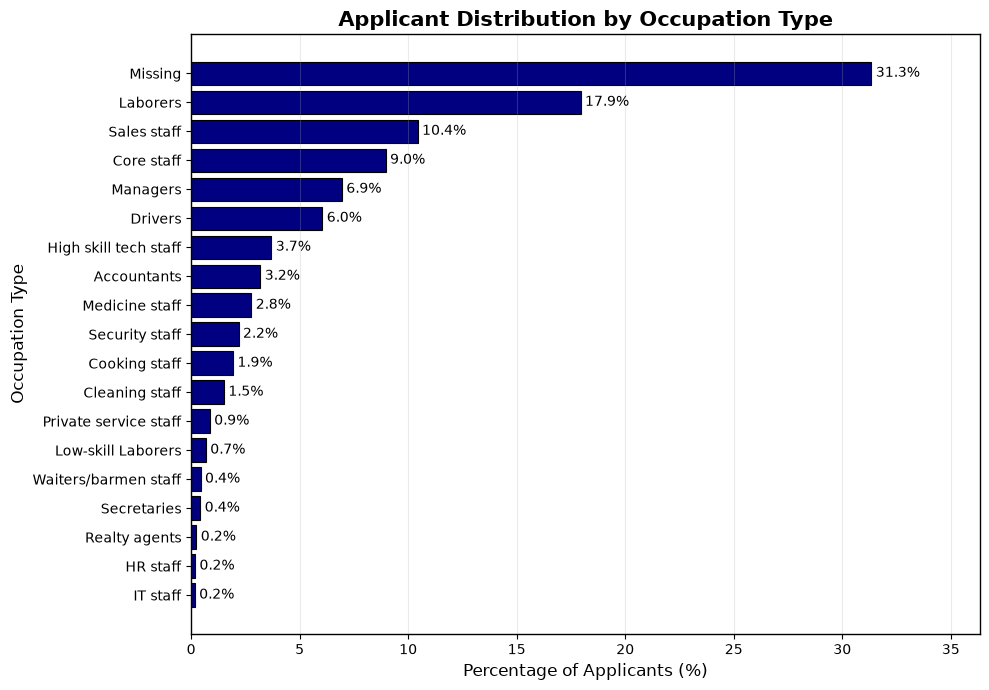

In [ ]:

# Calculate percentages of different categories of the OCCUPATION_TYPE
occupation_pct = (
    Train_Data["OCCUPATION_TYPE"]
    .fillna("Missing")
    .value_counts(normalize=True)
    .mul(100)
    .sort_values()
)

# Plot
fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    occupation_pct.index,
    occupation_pct.values,
    color="navy",
    edgecolor="black",
    linewidth=0.8
)

# Add percentage labels
for bar, value in zip(bars, occupation_pct.values):
    ax.text(
        value + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        fontsize=10
    )

ax.set_xlabel("Percentage of Applicants (%)", fontsize=12)
ax.set_ylabel("Occupation Type", fontsize=12)
ax.set_title(
    "Applicant Distribution by Occupation Type",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlim(0, occupation_pct.max() + 5)
ax.grid(axis="x", alpha=0.25)

# Keep a clean border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1)

plt.tight_layout()
plt.show()

#checking for summary
#numeric variable eda

In [52]:
Train_Data["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

In [53]:
Train_Data["AMT_CREDIT"].describe()

count    3.075110e+05
mean     5.990260e+05
std      4.024908e+05
min      4.500000e+04
25%      2.700000e+05
50%      5.135310e+05
75%      8.086500e+05
max      4.050000e+06
Name: AMT_CREDIT, dtype: float64

In [54]:
Train_Data["AMT_ANNUITY"].describe()

count    307499.000000
mean      27108.573909
std       14493.737315
min        1615.500000
25%       16524.000000
50%       24903.000000
75%       34596.000000
max      258025.500000
Name: AMT_ANNUITY, dtype: float64

In [55]:
Train_Data["AMT_GOODS_PRICE"].describe()

count    3.072330e+05
mean     5.383962e+05
std      3.694465e+05
min      4.050000e+04
25%      2.385000e+05
50%      4.500000e+05
75%      6.795000e+05
max      4.050000e+06
Name: AMT_GOODS_PRICE, dtype: float64

In [56]:
Train_Data["DAYS_BIRTH"].describe()

count    307511.000000
mean     -16036.995067
std        4363.988632
min      -25229.000000
25%      -19682.000000
50%      -15750.000000
75%      -12413.000000
max       -7489.000000
Name: DAYS_BIRTH, dtype: float64

In [57]:
(Train_Data['DAYS_BIRTH']/-365).describe()

count    307511.000000
mean         43.936973
std          11.956133
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: DAYS_BIRTH, dtype: float64

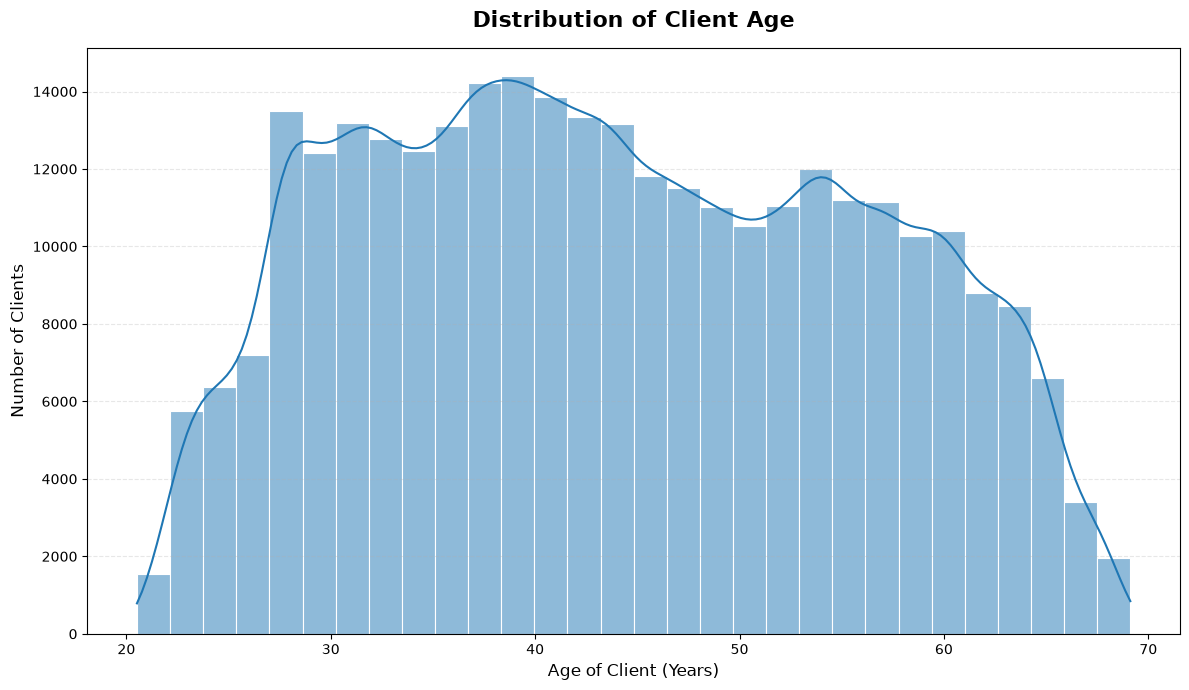

In [ ]:

# Convert DAYS_BIRTH to age in years
age = Train_Data["DAYS_BIRTH"] / -365

plt.figure(figsize=(12, 7))

sns.histplot(
    age,
    bins=30,
    kde=True,
    edgecolor="white",
    linewidth=0.8
)

plt.xlabel("Age of Client (Years)", fontsize=12)
plt.ylabel("Number of Clients", fontsize=12)
plt.title(
    "Distribution of Client Age",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()
plt.show()

Interpretation: People in the age range 30-40 years are the most applicants. Which seems pretty normal.

In [59]:
Train_Data["DAYS_EMPLOYED"].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [60]:
(Train_Data['DAYS_EMPLOYED']/365).describe()

count    307511.000000
mean        174.835742
std         387.056895
min         -49.073973
25%          -7.561644
50%          -3.323288
75%          -0.791781
max        1000.665753
Name: DAYS_EMPLOYED, dtype: float64

In [6]:
# Check an important data-quality issue in DAYS_EMPLOYED

sentinel_value = 365243

sentinel_count = (
    Train_Data["DAYS_EMPLOYED"] == sentinel_value
).sum()

sentinel_percent = (
    Train_Data["DAYS_EMPLOYED"] == sentinel_value
).mean() * 100

print(
    f"DAYS_EMPLOYED == {sentinel_value}: "
    f"{sentinel_count:,} rows ({sentinel_percent:.2f}%)"
)

DAYS_EMPLOYED == 365243: 55,374 rows (18.01%)


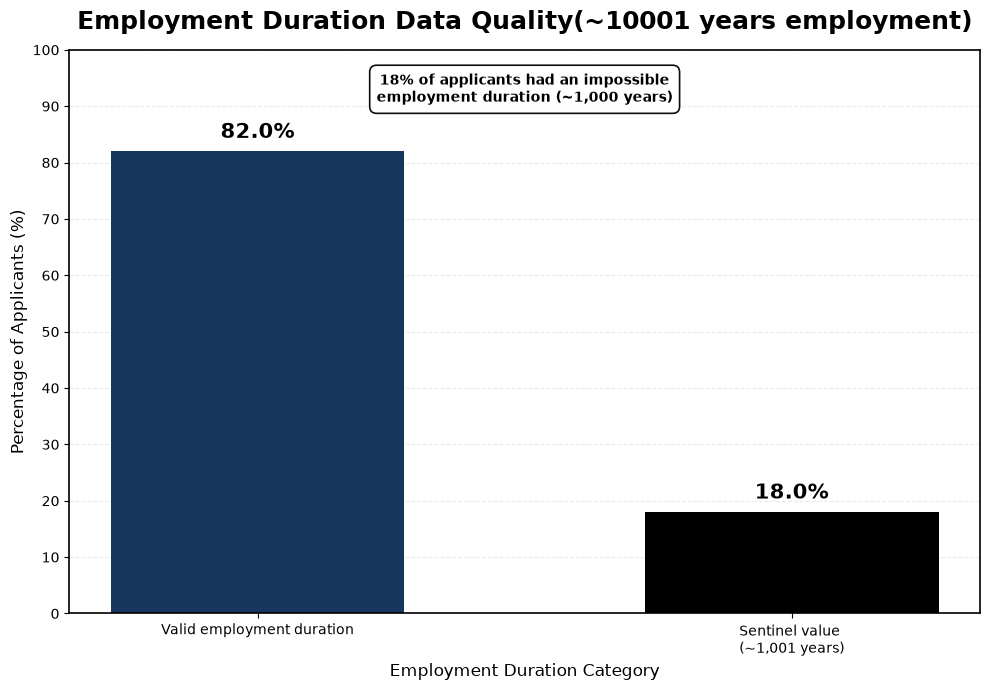

In [ ]:
# Graph of the valid employment and impossible duration of ~ 1001 years
sentinel_value = 365243

sentinel_value_pct = (
    Train_Data["DAYS_EMPLOYED"].eq(sentinel_value).mean() * 100
)

valid_pct = 100 - sentinel_value_pct

categories = [
    "Valid employment duration",
    "Sentinel value \n(~1,001 years)"
]

percentages = [
    valid_pct,
    sentinel_value_pct
]

# Create graph
fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.bar(
    categories,
    percentages,
    width=0.55,
    color = ["#17365D", "black"]
)

# Add percentage labels
for bar, value in zip(bars, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold"
    )

# Title
ax.set_title(
    "Employment Duration Data Quality(~10001 years employment)",
    fontsize=18,
    fontweight="bold",
    pad=15
)

# Axis labels
ax.set_xlabel(
    "Employment Duration Category",
    fontsize=12
)

ax.set_ylabel(
    "Percentage of Applicants (%)",
    fontsize=12
)

# Correct axis limits
ax.set_ylim(0, 100)

# Y-axis ticks
ax.set_yticks(range(0, 101, 10))

# Grid behind bars
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

# Keep a complete border
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2)

# Annotation
ax.text(
    0.5,
    0.93,
    "18% of applicants had an impossible\n"
    "employment duration (~1,000 years)",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="black",
        linewidth=1.2,
        alpha=0.95
    )
)

plt.tight_layout()
plt.show()

In [62]:
Train_Data["CNT_CHILDREN"].describe()

count    307511.000000
mean          0.417052
std           0.722121
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          19.000000
Name: CNT_CHILDREN, dtype: float64

In [63]:
Train_Data["CNT_FAM_MEMBERS"].describe()

count    307509.000000
mean          2.152665
std           0.910682
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max          20.000000
Name: CNT_FAM_MEMBERS, dtype: float64

#Categorical variables eda

In [64]:
categorical_cols_dtype = Train_Data.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols_dtype:
    print(col)


NAME_CONTRACT_TYPE
CODE_GENDER
FLAG_OWN_CAR
FLAG_OWN_REALTY
NAME_TYPE_SUITE
NAME_INCOME_TYPE
NAME_EDUCATION_TYPE
NAME_FAMILY_STATUS
NAME_HOUSING_TYPE
OCCUPATION_TYPE
WEEKDAY_APPR_PROCESS_START
ORGANIZATION_TYPE
FONDKAPREMONT_MODE
HOUSETYPE_MODE
WALLSMATERIAL_MODE
EMERGENCYSTATE_MODE


C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_3136\3782399429.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols_dtype = Train_Data.select_dtypes(


In [65]:

for col in categorical_cols_dtype:
    print(f"\n--- {col} ---")
    print(Train_Data[col].value_counts(dropna=False))


--- NAME_CONTRACT_TYPE ---
NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

--- CODE_GENDER ---
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

--- FLAG_OWN_CAR ---
FLAG_OWN_CAR
N    202924
Y    104587
Name: count, dtype: int64

--- FLAG_OWN_REALTY ---
FLAG_OWN_REALTY
Y    213312
N     94199
Name: count, dtype: int64

--- NAME_TYPE_SUITE ---
NAME_TYPE_SUITE
Unaccompanied      248526
Family              40149
Spouse, partner     11370
Children             3267
Other_B              1770
NaN                  1292
Other_A               866
Group of people       271
Name: count, dtype: int64

--- NAME_INCOME_TYPE ---
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

--- N

In [66]:
Train_Data["NAME_CONTRACT_TYPE"].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

In [67]:
corr = Train_Data[numeric_cols_dtype].corr()

In [68]:
target_corr = (
    corr["TARGET"]
    .drop("TARGET")
    .sort_values()
)

print(target_corr)

EXT_SOURCE_3                  -0.178919
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_1                  -0.155317
DAYS_EMPLOYED                 -0.044932
FLOORSMAX_AVG                 -0.044003
                                 ...   
DAYS_ID_PUBLISH                0.051457
DAYS_LAST_PHONE_CHANGE         0.055218
REGION_RATING_CLIENT           0.058899
REGION_RATING_CLIENT_W_CITY    0.060893
DAYS_BIRTH                     0.078239
Name: TARGET, Length: 105, dtype: float64


### Preprocessing


In [16]:
#Keep ID separately
Train_ID = Train_Data["SK_ID_CURR"]

In [17]:
#Target
y = Train_Data["TARGET"]

In [18]:
#Features
X = Train_Data.drop(columns=["SK_ID_CURR", "TARGET"])

In [19]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 120)
y shape: (307511,)


In [20]:
#Split into training and validation
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [21]:
# Checked for the shape of the splitted data
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (246008, 120)
X_val: (61503, 120)
y_train: (246008,)
y_val: (61503,)


In [22]:
def add_engineered_features(data):
    """Create interpretable features from application-level variables."""
    data = data.copy()

    # DAYS_EMPLOYED uses a sentinel value for a special case.
    data["DAYS_EMPLOYED"] = data["DAYS_EMPLOYED"].replace(
        sentinel_value,
        np.nan,
    )

    # Convert relative day counts into more interpretable years.
    data["AGE_YEARS"] = -data["DAYS_BIRTH"] / 365
    data["EMPLOYED_YEARS"] = (
        -data["DAYS_EMPLOYED"] / 365
    )

    # Financial ratios.
    #data["CREDIT_INCOME_RATIO"] = (
    #    data["AMT_CREDIT"]
    #    / data["AMT_INCOME_TOTAL"].replace(0, np.nan)
   # )

    #data["ANNUITY_INCOME_RATIO"] = (
    #    data["AMT_ANNUITY"]
    #    / data["AMT_INCOME_TOTAL"].replace(0, np.nan)
    #)

   # data["CREDIT_TERM_YEARS"] = (
   #     data["AMT_CREDIT"]
   #     / data["AMT_ANNUITY"].replace(0, np.nan)
    #)



    return data


X_train_fe = add_engineered_features(X_train)
X_val_fe = add_engineered_features(X_val)

print("Original feature count:", X_train.shape[1])
print("Feature count after engineering:", X_train_fe.shape[1])

new_features = sorted(
    set(X_train_fe.columns) - set(X_train.columns)
)

print("\nNew features:")
print(new_features)


Original feature count: 120
Feature count after engineering: 122

New features:
['AGE_YEARS', 'EMPLOYED_YEARS']


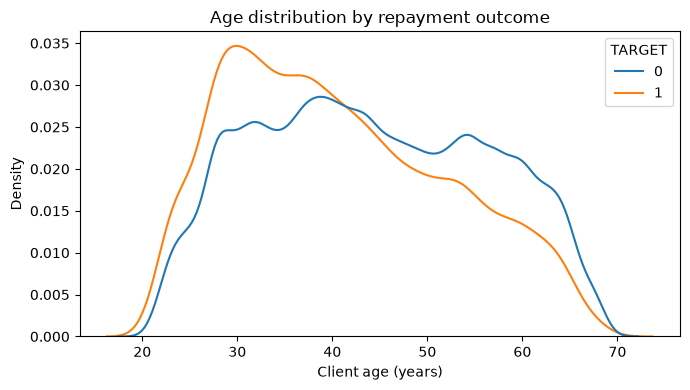

In [23]:
# --- Visualize relationships: does age relate to default risk? ---
train_eda = X_train_fe.copy()
train_eda['TARGET'] = y_train

fig, ax = plt.subplots(figsize=(7,4))
sns.kdeplot(data=train_eda, x='AGE_YEARS', hue='TARGET', common_norm=False, ax=ax)
ax.set_title('Age distribution by repayment outcome')
ax.set_xlabel('Client age (years)')
plt.tight_layout()
plt.show()


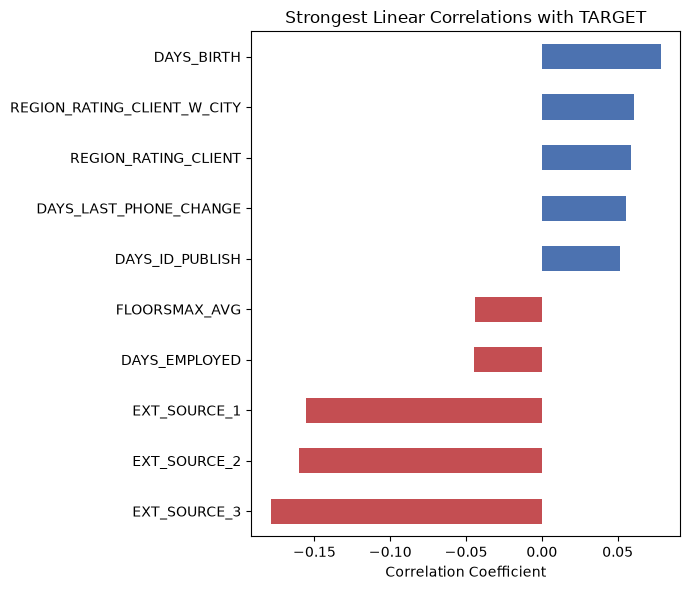

In [24]:
# --- Correlation analysis (numeric features vs. TARGET) ---
numeric_train = Train_Data.select_dtypes(include=np.number)

corr_with_target = (
    numeric_train.corr()['TARGET']
    .drop('TARGET')
    .sort_values()
)

fig, ax = plt.subplots(figsize=(7, 6))

# Top 5 negative + top 5 positive correlations
top_corr = pd.concat([
    corr_with_target.head(5),
    corr_with_target.tail(5)
])

colors = ['#C44E52' if v < 0 else '#4C72B0' for v in top_corr.values]

top_corr.plot(
    kind='barh',
    ax=ax,
    color=colors
)

ax.set_title('Strongest Linear Correlations with TARGET')
ax.set_xlabel('Correlation Coefficient')

plt.tight_layout()
plt.show()


In [25]:
## Grouped as Categorical and numerical variables
cat_cols = X_train_fe.select_dtypes(
    include=["object"]
).columns.tolist() + ["CNT_CHILDREN","CNT_FAM_MEMBERS", "REGION_RATING_CLIENT","REGION_RATING_CLIENT_W_CITY"]

print(cat_cols)

#ord_cols = ["AMT_REQ_CREDIT_BUREAU_HOUR","AMT_REQ_CREDIT_BUREAU_DAY","AMT_REQ_CREDIT_BUREAU_WEEK","AMT_REQ_CREDIT_BUREAU_MON","AMT_REQ_CREDIT_BUREAU_QRT","AMT_REQ_CREDIT_BUREAU_YEAR"]

binary_cols = ["FLAG_MOBIL","FLAG_EMP_PHONE","FLAG_WORK_PHONE","FLAG_CONT_MOBILE","FLAG_PHONE","FLAG_EMAIL","REG_REGION_NOT_LIVE_REGION","REG_REGION_NOT_WORK_REGION","LIVE_REGION_NOT_WORK_REGION",
"REG_CITY_NOT_LIVE_CITY",
"REG_CITY_NOT_WORK_CITY",
"LIVE_CITY_NOT_WORK_CITY","FLAG_DOCUMENT_2","FLAG_DOCUMENT_3",
"FLAG_DOCUMENT_4","FLAG_DOCUMENT_5","FLAG_DOCUMENT_6",
"FLAG_DOCUMENT_7","FLAG_DOCUMENT_8","FLAG_DOCUMENT_9","FLAG_DOCUMENT_10","FLAG_DOCUMENT_11","FLAG_DOCUMENT_12","FLAG_DOCUMENT_13",
"FLAG_DOCUMENT_14","FLAG_DOCUMENT_15","FLAG_DOCUMENT_16","FLAG_DOCUMENT_17",
"FLAG_DOCUMENT_18","FLAG_DOCUMENT_19","FLAG_DOCUMENT_20","FLAG_DOCUMENT_21"]

numeric_cols =X_train_fe.drop(columns=cat_cols+binary_cols).columns.tolist()
print(numeric_cols)
print(len(numeric_cols))


print(len(cat_cols)+len(numeric_cols)+len(binary_cols))

['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY']
['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'HOUR_APPR_PROCESS_START', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE

C:\Users\Prithvi Hegde\AppData\Local\Temp\ipykernel_29472\2261885513.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train_fe.select_dtypes(


In [26]:
#proportion of defaults is similar in train and validation.
print("Training target:")
print(y_train.value_counts(normalize=True))

print("\nValidation target:")
print(y_val.value_counts(normalize=True))

Training target:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Validation target:
TARGET
0    0.919272
1    0.080728
Name: proportion, dtype: float64


## Preprocessing pipeline

In [27]:
#Create preprocessing pipelines
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

#Categorical features
#Fill missing values with most frequent category
#One-hot encode

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ))
])

#ordinal_pipeline = Pipeline([
#    ("imputer", SimpleImputer(strategy="most_frequent")),
#    ("encoder", OrdinalEncoder(
#        handle_unknown="ignore"
#    ))
#])


#Combine them

preprocessor = ColumnTransformer([
    ("num_cols", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, cat_cols),
    ("binary", binary_pipeline, binary_cols),
    #("ordinal", ordinal_pipeline, ord_cols)
])

In [28]:
print("Overlap:", set(cat_cols) & set(binary_cols))

Overlap: set()


### Modeling

#Dummy Classifier

In [29]:
from sklearn.dummy import DummyClassifier

dummy_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

dummy_model.fit(X_train_fe, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_YEAR','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

In [ ]:
y_pred_dummy = dummy_model.predict(X_val_fe)

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_val, y_pred_dummy))
print("Precision:", precision_score(y_val, y_pred_dummy, zero_division=0))
print("Recall:", recall_score(y_val, y_pred_dummy, zero_division=0))
print("F1:", f1_score(y_val, y_pred_dummy, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred_dummy))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_dummy, zero_division=0))

Accuracy: 0.9192722306228964
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion Matrix:
[[56538     0]
 [ 4965     0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.00      0.00      0.00      4965

    accuracy                           0.92     61503
   macro avg       0.46      0.50      0.48     61503
weighted avg       0.85      0.92      0.88     61503



## Logistic Regression

Since it is highly imbalanced data, considered class_weight = balanced for all the model.

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("lr_model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

: 

In [ ]:
# To fit model 
lr_model.fit(X_train_fe, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('lr_model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_YEAR','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (defa

: 

In [32]:
## Predict validation results
y_val_pred = lr_model.predict(X_val_fe)

NameError: name 'lr_model' is not defined

In [31]:
# Predict default probability
y_val_prob = lr_model.predict_proba(X_val_fe)[:, 1]

NameError: name 'lr_model' is not defined

In [ ]:
## Import evaluation metrics
# Calculate ROC-AUC and PR-AUC
# Show confusion matrix
# Show classification report
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
# Calculate ROC-AUC and PR-AUC
print("ROC-AUC:",
      roc_auc_score(y_val, y_val_prob))

print("PR-AUC:",
      average_precision_score(y_val, y_val_prob))

# Show confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Repay", "Default"],
    yticklabels=["Repay", "Default"]
)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

NameError: name 'y_val_prob' is not defined

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import loguniform
import time

# Use the SAME 5-fold CV strategy for both searches so results are comparable.
# Cross-validation happens ONLY on X_train_fe/y_train -> the test set stays untouched.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------------------------------------------
# 1) RANDOMIZED SEARCH — broad, cheap exploration of the parameter space
# ---------------------------------------------------------------
# C = inverse regularization strength (small C -> stronger regularization).
# loguniform(1e-4, 1e2) samples C on a log scale, which is the right way to
# search C since its effect is roughly log-linear.
param_dist = {
    'lr_model__C': loguniform(1e-3, 1e2),
    'lr_model__class_weight': [None, 'balanced'],
}

random_search = RandomizedSearchCV(
    estimator=lr_model,
    param_distributions=param_dist,
    n_iter=20,                 # 20 random combos x 5 folds = 100 fits
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=1,
    #verbose=2,
)

t0 = time.time()
random_search.fit(X_train_fe, y_train)
print("RandomizedSearchCV time:", round(time.time() - t0, 1), "sec")
print("Best CV ROC-AUC:", round(random_search.best_score_, 4))
print("Best params found:", random_search.best_params_)

c:\Users\Narayani\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [22] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Narayani\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [16, 17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Narayani\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Narayani\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\prepr

RandomizedSearchCV time: 3659.1 sec
Best CV ROC-AUC: 0.7478
Best params found: {'lr_model__C': np.float64(0.04661686413912769), 'lr_model__class_weight': 'balanced'}


: 

In [ ]:

# ---------------------------------------------------------------
# 2) GRID SEARCH — narrow, exhaustive search AROUND what random search found
# ---------------------------------------------------------------
best_C = random_search.best_params_["lr_model__C"]
best_cw = random_search.best_params_["lr_model__class_weight"]

# Build a tight grid centered on best_C (half to double, on a log scale)
C_grid = [best_C * f for f in (0.25, 0.5, 1, 2, 4)]

param_grid = {
    'lr_model__C': C_grid,
    'lr_model__class_weight': [best_cw],   # keep the class_weight random search preferred
}

grid_search = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=2,
)

t0 = time.time()
grid_search.fit(X_train_fe, y_train)
print("GridSearchCV time:", round(time.time() - t0, 1), "sec")
print("Best CV ROC-AUC:", round(grid_search.best_score_, 4))
print("Best params:", grid_search.best_params_)



Fitting 5 folds for each of 5 candidates, totalling 25 fits
GridSearchCV time: 679.3 sec
Best CV ROC-AUC: 0.7478
Best params: {'lr_model__C': np.float64(0.023308432069563845), 'lr_model__class_weight': 'balanced'}


: 

In [ ]:
# ---------------------------------------------------------------
# 3) FINAL COMPARISON on the held-out test set (only look at this once!)
# ---------------------------------------------------------------
default_model = lr_model
default_model.fit(X_train_fe, y_train)
default_auc = roc_auc_score(y_val, default_model.predict_proba(X_val_fe)[:, 1])

tuned_model = grid_search.best_estimator_   # already refit on full X_train_fe by GridSearchCV
tuned_auc = roc_auc_score(y_val, tuned_model.predict_proba(X_val_fe)[:, 1])

print(f"Default LogisticRegression test ROC-AUC: {default_auc:.4f}")
print(f"Tuned   LogisticRegression test ROC-AUC: {tuned_auc:.4f}")
print(f"Improvement: {tuned_auc - default_auc:+.4f}")

c:\Users\Narayani\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Narayani\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Default LogisticRegression test ROC-AUC: 0.7501
Tuned   LogisticRegression test ROC-AUC: 0.7504
Improvement: +0.0002


: 

### Decision Tree Classifier

In [129]:
from sklearn.tree import DecisionTreeClassifier


dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

In [130]:
dt_pipeline.fit(X_train_fe, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_YEAR','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

In [131]:
y_pred = dt_pipeline.predict(X_val_fe)
y_prob = dt_pipeline.predict_proba(X_val_fe)[:, 1]

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


##Evaluate ROC-AUC : Baseline decision tree performance

In [342]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_prob))
print("Recall:", recall_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("F1:", f1_score(y_val, y_pred))
print("F2:", fbeta_score(y_val, y_pred, beta=2))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred))
print("classification report:\n", classification_report(y_val, y_pred))

Accuracy: 0.8570476236931531
ROC-AUC: 0.5409306245276951
Recall: 0.16394763343403826
Precision: 0.14922089825847845
F1: 0.1562380038387716
F2: 0.16077424451905983
Confusion Matrix:
 [[51897  4641]
 [ 4151   814]]
classification report:
               precision    recall  f1-score   support

           0       0.93      0.92      0.92     56538
           1       0.15      0.16      0.16      4965

    accuracy                           0.86     61503
   macro avg       0.54      0.54      0.54     61503
weighted avg       0.86      0.86      0.86     61503



Calculating training and validation probabilities
Here tree is overfitting and we are not restricting any parameters

In [163]:
from sklearn.metrics import roc_auc_score

# Training probabilities
y_train_prob = dt_pipeline.predict_proba(X_train_fe)[:, 1]
#print("y_train_prob", y_train_prob)

# Validation probabilities
y_val_prob = dt_pipeline.predict_proba(X_val_fe)[:, 1]

#rint("y_val_prob", y_val_prob)

train_roc_auc = roc_auc_score(y_train, y_train_prob)
val_roc_auc = roc_auc_score(y_val, y_val_prob)

print("Train ROC-AUC:", train_roc_auc)
print("Validation ROC-AUC:", val_roc_auc)
print("ROC-AUC Gap:", train_roc_auc - val_roc_auc)

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Train ROC-AUC: 1.0
Validation ROC-AUC: 0.5409306245276951
ROC-AUC Gap: 0.45906937547230486


Decision Tree: ##Hyperparameter tuning

Note: RandomizedSearchCV was used to efficiently tune hyperparameters while reducing computational time.

In [230]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_dist = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [5, 8, 10, 12, 15, 20],
    "model__min_samples_split": [50, 100, 200, 500],
    "model__min_samples_leaf": [20, 50, 100, 200, 500],
    "model__max_features": [None, "sqrt", "log2"]
}

In [231]:
#Stratified random search
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

dt_search = RandomizedSearchCV(
    estimator=dt_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

In [232]:
dt_search.fit(X_train_fe, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [5, 8, ...], 'model__max_features': [None, 'sqrt', ...], 'model__min_samples_leaf': [20, 50, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive 

In [139]:
print("Best parameters:")
print(dt_search.best_params_)

print("Best CV ROC-AUC:")
print(dt_search.best_score_)

Best parameters:
{'model__min_samples_split': 200, 'model__min_samples_leaf': 500, 'model__max_features': None, 'model__max_depth': 12, 'model__criterion': 'gini'}
Best CV ROC-AUC:
0.7142864032844709


In [225]:
best_dt = dt_search.best_estimator_

y_val_prob_dt = best_dt.predict_proba(X_val_fe)[:, 1]
y_val_pred_dt = best_dt.predict(X_val_fe)


c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Result: For Decision Tree Hyperparameter Tuning

In [343]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_val_pred_dt))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_dt))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_dt))
print("Recall:", recall_score(y_val, y_val_pred_dt))
print("Precision:", precision_score(y_val, y_val_pred_dt))
print("F1:", f1_score(y_val,y_val_pred_dt))
print("F2:", fbeta_score(y_val, y_val_pred_dt, beta=2))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_dt))
print("classification report:\n", classification_report(y_val, y_val_pred_dt))


Accuracy: 0.6646992829618067
ROC-AUC: 0.7222896171178368
PR-AUC: 0.20271182293420323
Recall: 0.6710976837865056
Precision: 0.14927646610814926
F1: 0.24422780913288866
F2: 0.39496455750219295
Confusion Matrix:
[[37549 18989]
 [ 1633  3332]]
classification report:
               precision    recall  f1-score   support

           0       0.96      0.66      0.78     56538
           1       0.15      0.67      0.24      4965

    accuracy                           0.66     61503
   macro avg       0.55      0.67      0.51     61503
weighted avg       0.89      0.66      0.74     61503



In [227]:
print(dt_search.best_params_)

{'model__min_samples_split': 200, 'model__min_samples_leaf': 500, 'model__max_features': None, 'model__max_depth': 12, 'model__criterion': 'gini'}


#Checking for overfitting

In [233]:
#Get predicted probabilities for the training data
y_train_prob_dt = best_dt.predict_proba(X_train_fe)[:, 1]

#Calculate ROC-AUC on training data
train_auc_dt = roc_auc_score(y_train, y_train_prob_dt)
#Calculate ROC-AUC on validation data
val_auc_dt = roc_auc_score(y_val, y_val_prob_dt)

print("Train ROC-AUC:", train_auc_dt)
print("Validation ROC-AUC:", val_auc_dt)
print("ROC-AUC Gap:", train_auc_dt - val_auc_dt)

Train ROC-AUC: 0.7519347468200783
Validation ROC-AUC: 0.7222896171178368
ROC-AUC Gap: 0.029645129702241535


Interpretation: Here we found that, there is improvement in the Decision Tree model from baseline decision tree model to hyperparameter tuned. model. So, Hyperparameter tuning can improvise the capacity of classification of unseen data.

The baseline Decision Tree severely overfit the training data. After hyperparameter tuning, validation ROC-AUC improved from 0.541 to 0.722, while the ROC-AUC gap decreased from 0.459 to 0.030. The tuned model achieved 67.1% recall, but precision remained low at 14.9%.

- CV ROC-AUC: 0.7143
- Validation ROC-AUC: 0.7223
- PR-AUC: 0.2027
- Recall: 0.6711
- Precision: 0.1493
- F1: 0.2442
- F2: 0.3950
- Train–validation ROC-AUC gap: 0.0296

For Business:The tuned Decision Tree substantially reduced overfitting and can identify around 67% of actual defaulters, making it useful for risk screening, although its low precision means additional assessment is needed before making lending decisions.

**************************************************************End of Decision Tree **************************************************

###Random Forest

#Random forest pipeline

In [165]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [171]:
rf_pipeline.fit(X_train_fe, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_YEAR','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

In [239]:
y_val_pred_rf = rf_pipeline.predict(X_val_fe)
y_val_prob_rf = rf_pipeline.predict_proba(X_val_fe)[:, 1]

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [344]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_val_pred_rf))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_rf))
print("PR-AUC:", average_precision_score(y_val, y_val_prob_rf))
print("Recall:", recall_score(y_val, y_val_pred_rf))
print("Precision:", precision_score(y_val, y_val_pred_rf))
print("F1:", f1_score(y_val, y_val_pred_rf))
print("F2:", fbeta_score(y_val, y_val_pred_rf, beta=2))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))
print("classification report:\n", classification_report(y_val, y_val_pred_rf))


Accuracy: 0.917890184218656
ROC-AUC: 0.7331667368277508
PR-AUC: 0.21003180582782632
Recall: 0.03746223564954683
Precision: 0.40700218818380746
F1: 0.06860936923644412
F2: 0.04577447457793966
Confusion Matrix:
[[56267   271]
 [ 4779   186]]
classification report:
               precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.41      0.04      0.07      4965

    accuracy                           0.92     61503
   macro avg       0.66      0.52      0.51     61503
weighted avg       0.88      0.92      0.89     61503



In [ ]:
#Check for overfiting
y_train_prob_rf = rf_pipeline.predict_proba(X_train_fe)[:, 1]

train_auc_rf = roc_auc_score(y_train, y_train_prob_rf)
val_auc_rf = roc_auc_score(y_val, y_val_prob_rf)

print("Train ROC-AUC:", train_auc_rf)
print("Validation ROC-AUC:", val_auc_rf)
print("ROC-AUC Gap:", train_auc_rf - val_auc_rf)

Train ROC-AUC: 1.0
Validation ROC-AUC: 0.7331667368277508
ROC-AUC Gap: 0.2668332631722492


#Random Forest : Hyperparameter Tuning

In [197]:
#param_dist_rf = {
 #   "model__n_estimators": [100, 150],
  #  "model__max_depth": [8, 12, 15],
   # "model__min_samples_split": [100, 200, 500],
    #"model__min_samples_leaf": [50, 100, 200],
    #"model__max_features": ["sqrt", "log2"],
    #"model__criterion": ["gini"]
#}

param_dist_rf = {
    "model__n_estimators": [50, 100],      # ✅ not 200-500
    "model__max_depth": [3, 5, 10],        # ✅ limit depth
    "model__max_features": ["sqrt"],       # ✅ fix one value
}

In [198]:
cv = StratifiedKFold(
    n_splits=3,       
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist_rf,
    n_iter=20,            
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,            
    error_score=0         
)

In [199]:
rf_search.fit(X_train_fe, y_train)

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\model_selection\_search.py:326: UserWarning: The total space of parameters 6 is smaller than n_iter=20. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 3 folds for each of 6 candidates, totalling 18 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [3, 5, ...], 'model__max_features': ['sqrt'], 'model__n_estimators': [50, 100]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",0
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters o

In [201]:
print("Best parameters:")
print(rf_search.best_params_)

print("Best CV ROC-AUC:")
print(rf_search.best_score_)

Best parameters:
{'model__n_estimators': 100, 'model__max_features': 'sqrt', 'model__max_depth': 10}
Best CV ROC-AUC:
0.7245394990521867


In [204]:
best_rf = rf_search.best_estimator_

y_pred_rf = best_rf.predict(X_val_fe)
y_prob_rf = best_rf.predict_proba(X_val_fe)[:, 1]

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Result: Hyperparameter tuning
Random Forest

In [346]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)
print("Accuracy:", accuracy_score(y_val,y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_val, y_prob_rf))
print("Recall:", recall_score(y_val, y_pred_rf))
print("Precision:", precision_score(y_val, y_pred_rf))
print("F1:", f1_score(y_val, y_pred_rf))
print("F2:", fbeta_score(y_val, y_pred_rf, beta=2))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_rf))
print("classification report:\n", classification_report(y_val, y_pred_rf))

Accuracy: 0.7000634115409005
ROC-AUC: 0.7278816087012142
Recall: 0.6245720040281973
Precision: 0.15753911806543386
F1: 0.25161264148647006
F2: 0.39209488165081935
Confusion Matrix:
[[39955 16583]
 [ 1864  3101]]
classification report:
               precision    recall  f1-score   support

           0       0.96      0.71      0.81     56538
           1       0.16      0.62      0.25      4965

    accuracy                           0.70     61503
   macro avg       0.56      0.67      0.53     61503
weighted avg       0.89      0.70      0.77     61503



#Feature importance: random forest

In [347]:
best_rf = rf_random.best_estimator_

rf_model = best_rf.named_steps["model"]
preprocessor_fitted = best_rf.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

importance.head(20)

,Feature,Importance
13,num_cols__EXT_SOURCE_3,0.125616
12,num_cols__EXT_SOURCE_2,0.108763
11,num_cols__EXT_SOURCE_1,0.043036
6,num_cols__DAYS_EMPLOYED,0.037098
69,num_cols__EMPLOYED_YEARS,0.030381
68,num_cols__AGE_YEARS,0.028696
5,num_cols__DAYS_BIRTH,0.028635
3,num_cols__AMT_GOODS_PRICE,0.025197
61,num_cols__DAYS_LAST_PHONE_CHANGE,0.025191
1,num_cols__AMT_CREDIT,0.023576


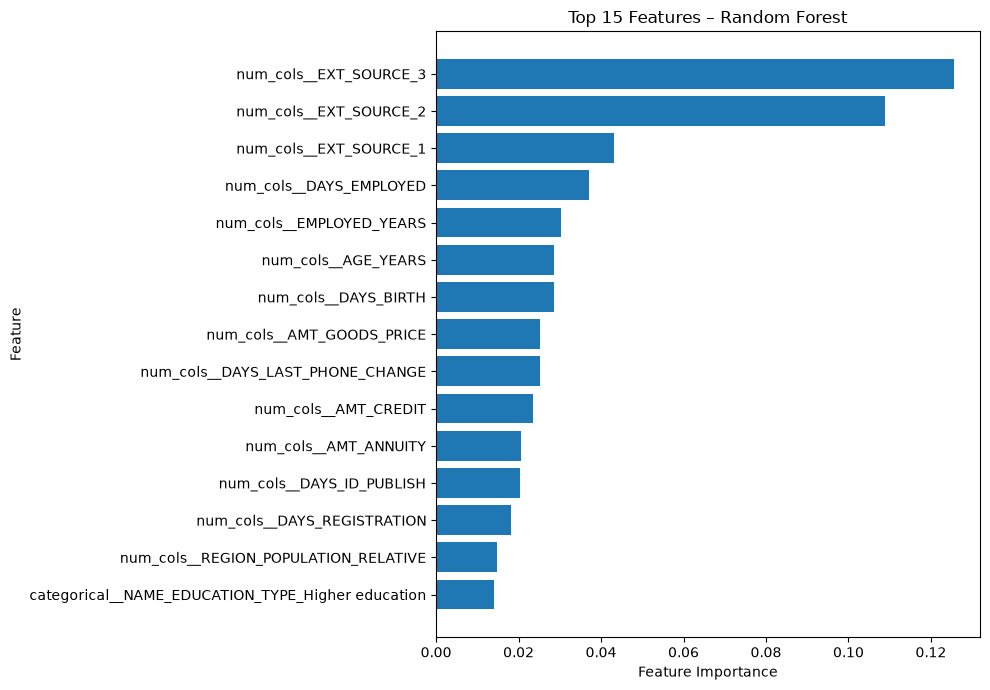

In [348]:
## Feature importance
import matplotlib.pyplot as plt

top_15 = importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_15["Feature"], top_15["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features – Random Forest")
plt.tight_layout()
plt.show()

************************************************************** End of Random Forest *****************************************

##XGBoost: Baseline 

In [211]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="auc",
        random_state=42,
        n_jobs=-1
    ))
])

In [213]:
xgb_pipeline.fit(X_train_fe, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_YEAR','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

In [215]:
y_pred_xgb = xgb_pipeline.predict(X_val_fe)

y_prob_xgb = xgb_pipeline.predict_proba(X_val_fe)[:, 1]

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [17] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [349]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_val, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_val, y_prob_xgb))
print("Recall:", recall_score(y_val, y_pred_xgb))
print("Precision:", precision_score(y_val, y_pred_xgb))
print("F1:", f1_score(y_val, y_pred_xgb))
print("F2:", fbeta_score(y_val, y_pred_xgb, beta=2))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_xgb))
print("classification report:\n", classification_report(y_val, y_pred_xgb))

Accuracy: 0.6952506381802513
ROC-AUC: 0.7570534029693224
Recall: 0.687411883182276
Precision: 0.16564744709765095
F1: 0.26696390159959327
F2: 0.42173289837880584
Confusion Matrix:
[[39347 17191]
 [ 1552  3413]]
classification report:
               precision    recall  f1-score   support

           0       0.96      0.70      0.81     56538
           1       0.17      0.69      0.27      4965

    accuracy                           0.70     61503
   macro avg       0.56      0.69      0.54     61503
weighted avg       0.90      0.70      0.76     61503



Feature Importance: XGBoost

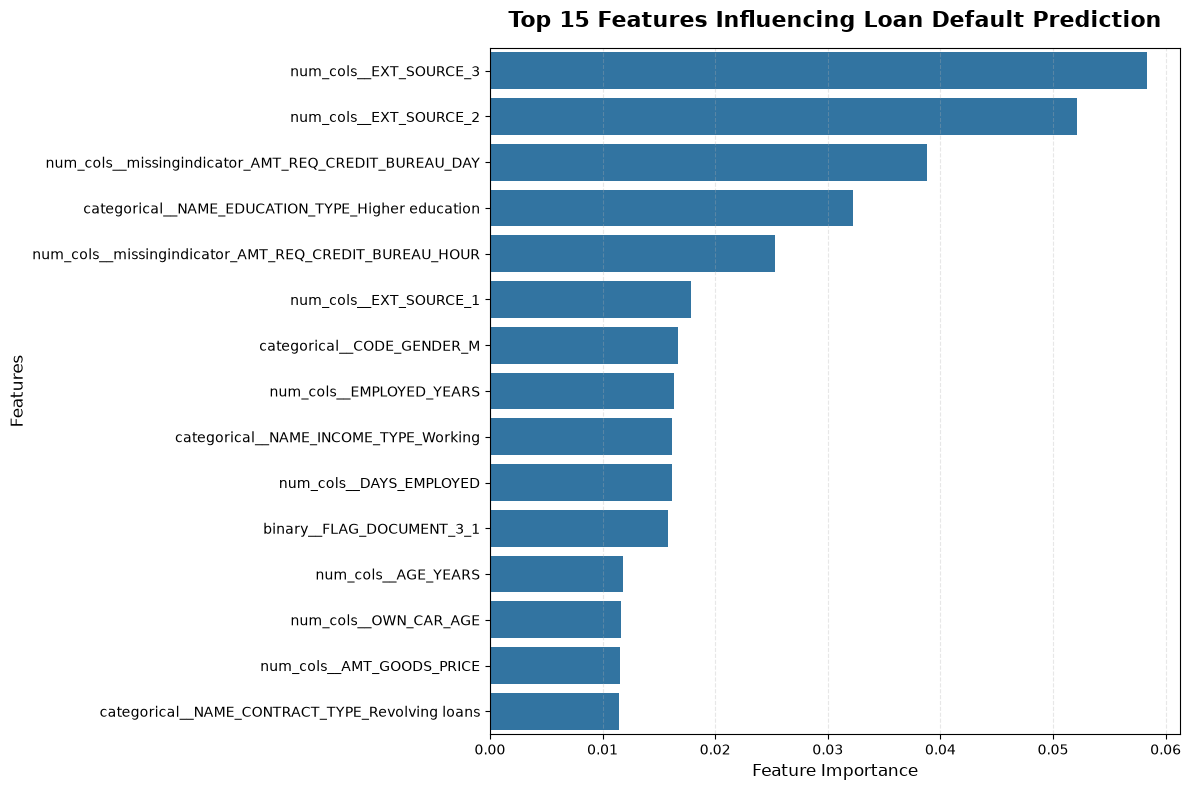

In [317]:
### Get feature importance
xgb_pipeline.fit(X_train_fe, y_train)

# Get the fitted preprocessor
preprocessor_fitted = xgb_pipeline.named_steps["preprocessor"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Get XGBoost feature importance
importance = xgb_pipeline.named_steps["model"].feature_importances_


### Create a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    "Importance",
    ascending=False
)


### Plot Top 15 Features

top_features = feature_importance_df.head(15).sort_values(
    "Importance",
    ascending=False
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Features Influencing Loan Default Prediction",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Features", fontsize=12)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [ ]:
# Test on new applications
##Test Data

In [262]:
print(Test_Data.shape)
print(Test_Data.head())
print(Test_Data.columns.tolist())

(48744, 121)
   SK_ID_CURR NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  \
0      100001         Cash loans           F            N               Y   
1      100005         Cash loans           M            N               Y   
2      100013         Cash loans           M            Y               Y   
3      100028         Cash loans           F            N               Y   
4      100038         Cash loans           M            Y               N   

   CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  \
0             0          135000.0    568800.0      20560.5         450000.0   
1             0           99000.0    222768.0      17370.0         180000.0   
2             0          202500.0    663264.0      69777.0         630000.0   
3             2          315000.0   1575000.0      49018.5        1575000.0   
4             1          180000.0    625500.0      32067.0         625500.0   

   ... FLAG_DOCUMENT_18 FLAG_DOCUMENT_19 FLAG_DOC

In [ ]:
print("TARGET" in Test_Data.columns)


False


#### Feature Engineering for Test_Data

In [270]:
Test_Data_fe = add_engineered_features(Test_Data)

print(Test_Data.shape)

print([
    col for col in Test_Data.columns
    if col in [
        "AGE_YEARS",
        "EMPLOYED_YEARS",
        #"CREDIT_INCOME_RATIO",
        #"ANNUITY_INCOME_RATIO",
        #"CREDIT_TERM_YEARS"
    ]
])

(48744, 123)
['AGE_YEARS', 'EMPLOYED_YEARS']


## Confirming one more time for the shapes of the data

In [280]:
train_features = set(X_train_fe.columns) #- {"SK_ID_CURR"}
test_features = set(Test_Data_fe.columns) - {"SK_ID_CURR"}

print("Same features:", train_features == test_features)

Same features: True


In [281]:
print("Only in Train:")
print(train_features - test_features)

print("\nOnly in Test:")
print(test_features - train_features)

Only in Train:
set()

Only in Test:
set()


## Checking once again for columns in both data

In [282]:
print(X_train_fe.columns.equals(Test_Data_fe.columns))

False


In [283]:
print(
    set(X_train_fe.columns) == set(Test_Data_fe.columns)
)

False


In [284]:
Test_Data_fe = Test_Data_fe[X_train_fe.columns]

In [285]:
print(X_train_fe.columns.equals(Test_Data_fe.columns))

True


In [291]:
# Comparing both columns
comparison = pd.DataFrame({
    "Train Columns": X_train_fe.columns,
    "Test Columns": Test_Data_fe.columns
})

comparison["Same"] = (
    comparison["Train Columns"] == comparison["Test Columns"]
)

print(comparison.to_string(index=False))

print("Train shape:", X_train_fe.shape)
print("Test shape:", Test_Data_fe.shape)

               Train Columns                 Test Columns  Same
          NAME_CONTRACT_TYPE           NAME_CONTRACT_TYPE  True
                 CODE_GENDER                  CODE_GENDER  True
                FLAG_OWN_CAR                 FLAG_OWN_CAR  True
             FLAG_OWN_REALTY              FLAG_OWN_REALTY  True
                CNT_CHILDREN                 CNT_CHILDREN  True
            AMT_INCOME_TOTAL             AMT_INCOME_TOTAL  True
                  AMT_CREDIT                   AMT_CREDIT  True
                 AMT_ANNUITY                  AMT_ANNUITY  True
             AMT_GOODS_PRICE              AMT_GOODS_PRICE  True
             NAME_TYPE_SUITE              NAME_TYPE_SUITE  True
            NAME_INCOME_TYPE             NAME_INCOME_TYPE  True
         NAME_EDUCATION_TYPE          NAME_EDUCATION_TYPE  True
          NAME_FAMILY_STATUS           NAME_FAMILY_STATUS  True
           NAME_HOUSING_TYPE            NAME_HOUSING_TYPE  True
  REGION_POPULATION_RELATIVE   REGION_PO

## XGB for test data

In [221]:
xgb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](122,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',..., 'AMT_REQ_CREDIT_BUREAU_YEAR','AGE_YEARS','EMPLOYED_YEARS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,122
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cols', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

In [292]:
test_prob = xgb_pipeline.predict_proba(Test_Data_fe)[:, 1]

c:\Users\Prithvi Hegde\neuefische_course\ML_Project_Home_Credit_Default_Risk\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [16, 17, 19] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [313]:
# print("IDs:", len(test_ids))
# print("Probabilities:", len(test_prob))

In [ ]:
#Jinja2 helps Python create dynamic formatted content, such as HTML pages or tables.
pip install jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)

   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Risk calculated for each SK_ID_CURR
test_ids = Test_Data["SK_ID_CURR"]
best_threshold = 0.42

# Create predictions DataFrame
test_predictions = pd.DataFrame({
    "SK_ID_CURR": test_ids.values,
    "Predicted_Probability": test_prob
})

# Business decision
test_predictions["Risk_Decision"] = np.where(
    test_predictions["Predicted_Probability"] >= best_threshold,
    "Flag for Review",
    "Lower Risk"
)

# Binary prediction
test_predictions["Predicted_Default"] = (
    test_predictions["Predicted_Probability"] >= best_threshold
).astype(int)

test_predictions.head(5).style.set_properties(
    **{'text-align': 'center'}
).set_table_styles([
    {
        'selector': 'th',
        'props': [('text-align', 'center')]
    }
])

,SK_ID_CURR,Predicted_Probability,Risk_Decision,Predicted_Default
0,100001,0.340609,Lower Risk,0
1,100005,0.576185,Flag for Review,1
2,100013,0.129067,Lower Risk,0
3,100028,0.296704,Lower Risk,0
4,100038,0.623841,Flag for Review,1


In [314]:
# print("Predicted defaults:", test_pred.sum())
# print("Predicted non-defaults:", (test_pred == 0).sum())
# total = len(test_pred)

# print("Predicted defaults:", test_pred.sum())
# print("Predicted default rate:", test_pred.mean() * 100, "%")

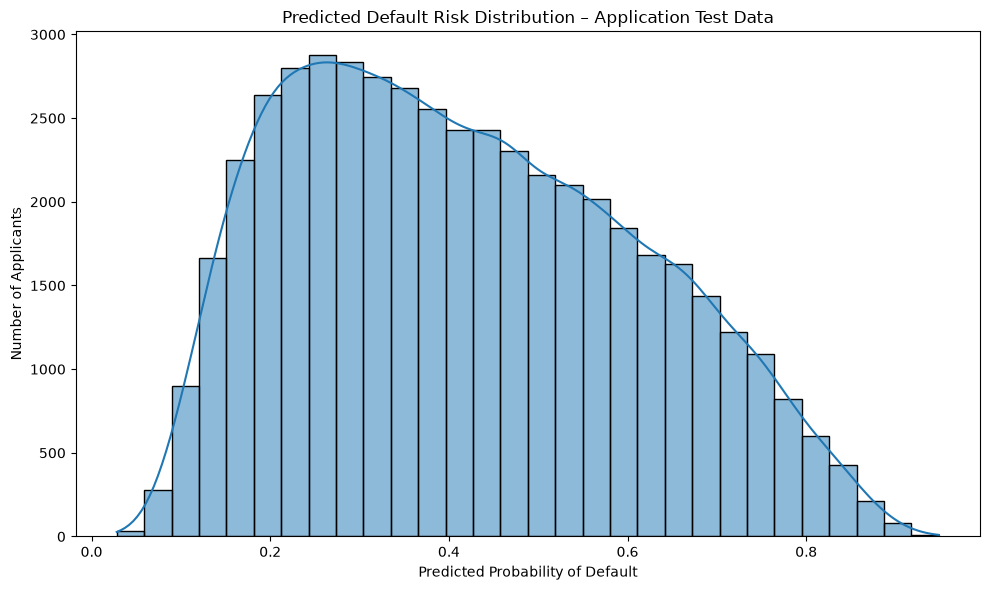

In [ ]:
#Predicted Default Risk Distribution for Test Data
plt.figure(figsize=(10, 6))

sns.histplot(
    test_prob,
    bins=30,
    kde=True
)

plt.xlabel("Predicted Probability of Default")
plt.ylabel("Number of Applicants")
plt.title("Predicted Default Risk Distribution – Application Test Data")

plt.tight_layout()
plt.show()